In [1]:
import os

# src klasörünü oluştur
os.makedirs('src', exist_ok=True)

# utils.py dosyasını doğrudan içeri yaz
utils_code = '''import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    adjusted_rand_score, silhouette_score, roc_curve, auc
)

SEEDS = [42, 52, 62]

def load_data(dataset_name="breast_cancer"):
    if dataset_name == "breast_cancer":
        raw = load_breast_cancer()
    elif dataset_name == "wine":
        raw = load_wine()
    else:
        raise ValueError("Desteklenmeyen veri seti: " + dataset_name)
    X = pd.DataFrame(raw.data, columns=raw.feature_names)
    y = pd.Series(raw.target, name="target")
    return X, y, raw.target_names

def prepare_dataset_splits(X, y, seeds=SEEDS):
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=42
    )
    splits = {'test': (X_test, y_test), 'by_seed': {}}
    for s in seeds:
        X_tr, X_va, y_tr, y_va = train_test_split(
            X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=s
        )
        splits['by_seed'][s] = {'X_train': X_tr, 'X_val': X_va, 'y_train': y_tr, 'y_val': y_va}
    return splits

def get_split_summary_table(dataset_name, splits, seeds=SEEDS):
    rows = []
    total_len = len(splits['test'][0]) + len(splits['by_seed'][seeds[0]]['X_train']) + len(splits['by_seed'][seeds[0]]['X_val'])
    for s in seeds:
        tr_x, tr_y = splits['by_seed'][s]['X_train'], splits['by_seed'][s]['y_train']
        va_x, va_y = splits['by_seed'][s]['X_val'], splits['by_seed'][s]['y_val']
        te_x, te_y = splits['test']
        for name, sub_x, sub_y in [('Train', tr_x, tr_y), ('Validation', va_x, va_y), ('Test', te_x, te_y)]:
            class_counts = sub_y.value_counts().to_dict()
            rows.append({
                'Dataset': dataset_name,
                'Seed': s,
                'Subset': name,
                'Sample Count': len(sub_x),
                'Percentage': round((len(sub_x) / total_len) * 100, 2),
                'Class Distribution': str(class_counts)
            })
    return pd.DataFrame(rows)

def scale_subsets(splits, seeds=SEEDS):
    scaled_data = {'by_seed': {}}
    scalers = {}
    for s in seeds:
        scaler = StandardScaler()
        X_train = splits['by_seed'][s]['X_train']
        X_val = splits['by_seed'][s]['X_val']
        X_train_sc = pd.DataFrame(scaler.fit_transform(X_train), index=X_train.index, columns=X_train.columns)
        X_val_sc = pd.DataFrame(scaler.transform(X_val), index=X_val.index, columns=X_val.columns)
        scaled_data['by_seed'][s] = {'X_train_scaled': X_train_sc, 'X_val_scaled': X_val_sc}
        scalers[s] = scaler

    X_test, _ = splits['test']
    X_test_sc = pd.DataFrame(scalers[42].transform(X_test), index=X_test.index, columns=X_test.columns)
    scaled_data['test_scaled'] = X_test_sc
    return scaled_data, scalers

def compute_classification_metrics(y_true, y_pred, y_prob, dataset_name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    if dataset_name == "breast_cancer":
        y_true_binary = (y_true == 0).astype(int)
        prob_malignant = y_prob[:, 0]
        roc = roc_auc_score(y_true_binary, prob_malignant)
    else:
        roc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")

    return {'accuracy': acc, 'macro_precision': prec, 'macro_recall': rec, 'macro_f1': f1, 'roc_auc': roc}

def get_model_instances(seed):
    models = []
    for depth in [2, 3, 5, 10, None]:
        models.append({'algo': 'DecisionTree', 'param': f'max_depth_{depth}', 'model': DecisionTreeClassifier(max_depth=depth, random_state=seed)})
    for k in [1, 3, 5, 7, 11]:
        models.append({'algo': 'KNN', 'param': f'k_{k}', 'model': KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')})
    models.append({'algo': 'GaussianNB', 'param': 'default', 'model': GaussianNB()})
    return models

def run_classifier_experiments(dataset_name, splits, scaled_data, seeds=SEEDS):
    runs = []
    fitted_models_s42 = {}
    for s in seeds:
        y_train = splits['by_seed'][s]['y_train']
        y_val = splits['by_seed'][s]['y_val']
        representations = {
            'unscaled': (splits['by_seed'][s]['X_train'], splits['by_seed'][s]['X_val']),
            'scaled': (scaled_data['by_seed'][s]['X_train_scaled'], scaled_data['by_seed'][s]['X_val_scaled'])
        }
        for rep_name, (X_tr, X_va) in representations.items():
            for cfg in get_model_instances(s):
                algo, param, clf = cfg['algo'], cfg['param'], cfg['model']
                run_id = f"{dataset_name}_{algo.lower()}_{rep_name}_{param}_s{s}"
                clf.fit(X_tr, y_train)

                if s == 42:
                    fitted_models_s42[f"{dataset_name}_{algo}_{rep_name}_{param}"] = clf

                y_tr_pred = clf.predict(X_tr)
                tr_acc = accuracy_score(y_train, y_tr_pred)
                tr_f1 = f1_score(y_train, y_tr_pred, average="macro", zero_division=0)

                y_va_pred = clf.predict(X_va)
                y_va_prob = clf.predict_proba(X_va)
                val_metrics = compute_classification_metrics(y_val, y_va_pred, y_va_prob, dataset_name)

                runs.append({
                    'run_id': run_id, 'dataset': dataset_name, 'algorithm': algo, 'representation': rep_name,
                    'parameter': param, 'seed': s, 'train_accuracy': tr_acc, 'train_macro_f1': tr_f1,
                    'val_accuracy': val_metrics['accuracy'], 'val_macro_precision': val_metrics['macro_precision'],
                    'val_macro_recall': val_metrics['macro_recall'], 'val_macro_f1': val_metrics['macro_f1'],
                    'val_roc_auc': val_metrics['roc_auc']
                })
    return pd.DataFrame(runs), fitted_models_s42

def summarize_classifiers(df_runs):
    group_cols = ['dataset', 'algorithm', 'representation', 'parameter']
    metrics = ['train_accuracy', 'train_macro_f1', 'val_accuracy', 'val_macro_precision', 'val_macro_recall', 'val_macro_f1', 'val_roc_auc']
    summary_rows = []
    for keys, group in df_runs.groupby(group_cols, as_index=False):
        row = dict(zip(group_cols, keys))
        for m in metrics:
            row[f"{m}_mean"] = group[m].mean()
            row[f"{m}_std"] = group[m].std(ddof=1)
        summary_rows.append(row)
    df_summary = pd.DataFrame(summary_rows)
    return df_summary.sort_values(
        by=['val_macro_f1_mean', 'val_accuracy_mean', 'val_macro_f1_std', 'parameter'],
        ascending=[False, False, True, True]
    ).reset_index(drop=True)

def run_kmeans_experiments(dataset_name, splits, scaled_data, seeds=SEEDS):
    n_clusters = 2 if dataset_name == "breast_cancer" else 3
    kmeans_runs = []
    fitted_kmeans_s42 = {}
    for s in seeds:
        y_val = splits['by_seed'][s]['y_val']
        representations = {
            'unscaled': (splits['by_seed'][s]['X_train'], splits['by_seed'][s]['X_val']),
            'scaled': (scaled_data['by_seed'][s]['X_train_scaled'], scaled_data['by_seed'][s]['X_val_scaled'])
        }
        for rep_name, (X_tr, X_va) in representations.items():
            km = KMeans(n_clusters=n_clusters, random_state=s, n_init=10)
            km.fit(X_tr)
            if s == 42:
                fitted_kmeans_s42[rep_name] = km
            val_preds = km.predict(X_va)
            kmeans_runs.append({
                'run_id': f"{dataset_name}_kmeans_{rep_name}_s{s}", 'dataset': dataset_name,
                'representation': rep_name, 'seed': s, 'n_clusters': n_clusters,
                'train_inertia': km.inertia_,
                'val_ari': adjusted_rand_score(y_val, val_preds),
                'val_silhouette': silhouette_score(X_va, val_preds) if len(np.unique(val_preds)) > 1 else np.nan
            })
    return pd.DataFrame(kmeans_runs), fitted_kmeans_s42
'''

with open('src/utils.py', 'w') as f:
    f.write(utils_code)

print("src/utils.py başarıyla oluşturuldu!")

src/utils.py başarıyla oluşturuldu!


In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Az önce oluşturduğumuz src/utils.py dosyasını çalışma yoluna ekleyip içeri alıyoruz
sys.path.append('src')
from utils import (
    load_data,
    prepare_dataset_splits,
    get_split_summary_table,
    scale_subsets,
    run_classifier_experiments,
    summarize_classifiers,
    run_kmeans_experiments
)

# Grafiklerin düzgün görünmesi için stil ayarları
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# 1. Loading the Datasets

In [3]:
# 1.1 & 1.2: Veriyi scikit-learn üzerinden yükleme ve DataFrame oluşturma
X, y, target_names = load_data("breast_cancer")

print(f"Dataset Shape (Rows, Columns): {X.shape}")
print(f"Target Names and Mapping: { {i: name for i, name in enumerate(target_names)} }")
print(f"Class Sample Counts:\n{y.value_counts().rename(index={0: 'malignant (0)', 1: 'benign (1)'})}\n")

print("--- First 5 Rows of Feature Matrix (X) ---")
display(X.head())

Dataset Shape (Rows, Columns): (569, 30)
Target Names and Mapping: {0: np.str_('malignant'), 1: np.str_('benign')}
Class Sample Counts:
target
benign (1)       357
malignant (0)    212
Name: count, dtype: int64

--- First 5 Rows of Feature Matrix (X) ---


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


> **Interpretation for Section 1:**
> The Breast Cancer Wisconsin dataset contains 569 samples and 30 continuous numerical features computed from digitized images of fine needle aspirates (FNA) of breast masses. The target variable is binary: Class 0 represents **malignant** (212 samples, ~37.26%) and Class 1 represents **benign** (357 samples, ~62.74%). As specified in the assignment guidelines, original class labels are strictly preserved, and Class 0 (malignant) is designated as the positive class for subsequent error and ROC-AUC analyses.

# 2. Dataset Quality Checks


In [4]:
# 2.1: Eksik değer ve çift (duplicate) satır kontrolü
missing_counts = X.isnull().sum()
duplicate_count = X.duplicated().sum()

print("--- Data Quality: Missing Values & Duplicates ---")
print(f"Total Duplicate Rows: {duplicate_count}")
print(f"Total Columns with Missing Values: {(missing_counts > 0).sum()}")

# 2.3: Veri tiplerinin kontrolü
print("\n--- Data Quality: Feature Data Types ---")
dtype_counts = X.dtypes.value_counts()
print(f"Data types distribution in features:\n{dtype_counts}")
print(f"Numerical features: {len(X.select_dtypes(include=[np.number]).columns)} / Categorical features: {len(X.select_dtypes(include=['object', 'category']).columns)}")

--- Data Quality: Missing Values & Duplicates ---
Total Duplicate Rows: 0
Total Columns with Missing Values: 0

--- Data Quality: Feature Data Types ---
Data types distribution in features:
float64    30
Name: count, dtype: int64
Numerical features: 30 / Categorical features: 0


In [5]:
# 2.2: IQR yöntemiyle potansiyel aykırı değerlerin tespiti (Silme veya kırpma yapılmaz)
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

# Alt ve üst sınırlar
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_per_col = ((X < lower_bound) | (X > upper_bound)).sum()
outliers_summary = pd.DataFrame({
    'Q1': Q1,
    'Q3': Q3,
    'IQR': IQR,
    'Lower Bound': lower_bound,
    'Upper Bound': upper_bound,
    'Outlier Count': outliers_per_col,
    'Outlier %': (outliers_per_col / len(X) * 100).round(2)
})

print("Top 10 Features with Most Potential Outliers:")
display(outliers_summary.sort_values(by='Outlier Count', ascending=False).head(10))

Top 10 Features with Most Potential Outliers:


,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
area error,17.850000,45.190000,27.340000,-23.160000,86.200000,65,11.42
radius error,0.232400,0.478900,0.246500,-0.137350,0.848650,38,6.68
perimeter error,1.606000,3.357000,1.751000,-1.020500,5.983500,38,6.68
worst area,515.300000,1084.000000,568.700000,-337.750000,1937.050000,35,6.15
smoothness error,0.005169,0.008146,0.002977,0.000703,0.012612,30,5.27
fractal dimension error,0.002248,0.004558,0.002310,-0.001217,0.008023,28,4.92
compactness error,0.013080,0.032450,0.019370,-0.015975,0.061505,28,4.92
symmetry error,0.015160,0.023480,0.008320,0.002680,0.035960,27,4.75
mean area,420.300000,782.700000,362.400000,-123.300000,1326.300000,25,4.39
worst fractal dimension,0.071460,0.092080,0.020620,0.040530,0.123010,24,4.22


> **Interpretation for Section 2:**
> - **Missing Values and Duplicates:** There are 0 missing values across all 30 features, and 0 duplicate rows. As explicitly instructed in Section 2.1, no artificial imputation is performed.
> - **Feature Types:** All 30 features are strictly floating-point numbers (`float64`). There are no categorical features present in the raw matrix.
> - **Outlier Discussion:** Potential outliers were identified via the $1.5 \times \text{IQR}$ rule. Several features related to cell area, perimeter, and error dimensions (e.g., `area error`, `perimeter error`) exhibit extreme right-skewed values. In distance-based algorithms such as KNN and centroid-based clustering (K-Means), these unscaled large magnitudes could dominate Euclidean distances if left unnormalized. In contrast, tree-based models (Decision Trees) are invariant to monotonic feature scales and robust against isolated outliers. Following Section 2.2, no observations are deleted or clipped, preserving biological variance across samples.


# 3. Exploratory Data Analysis (EDA)

In [6]:
# 3.1: Mean, median, min, max, std, Q1 ve Q3 hesaplanması
desc_stats = pd.DataFrame({
    'Mean': X.mean(),
    'Median': X.median(),
    'Min': X.min(),
    'Max': X.max(),
    'Std': X.std(),
    'Q1': X.quantile(0.25),
    'Q3': X.quantile(0.75)
})

print("--- Descriptive Statistics for All 30 Features (First 10 shown) ---")
display(desc_stats.head(10))

--- Descriptive Statistics for All 30 Features (First 10 shown) ---


,Mean,Median,Min,Max,Std,Q1,Q3
mean radius,14.127292,13.37000,6.98100,28.11000,3.524049,11.70000,15.78000
mean texture,19.289649,18.84000,9.71000,39.28000,4.301036,16.17000,21.80000
mean perimeter,91.969033,86.24000,43.79000,188.50000,24.298981,75.17000,104.10000
mean area,654.889104,551.10000,143.50000,2501.00000,351.914129,420.30000,782.70000
mean smoothness,0.096360,0.09587,0.05263,0.16340,0.014064,0.08637,0.10530
mean compactness,0.104341,0.09263,0.01938,0.34540,0.052813,0.06492,0.13040
mean concavity,0.088799,0.06154,0.00000,0.42680,0.079720,0.02956,0.13070
mean concave points,0.048919,0.03350,0.00000,0.20120,0.038803,0.02031,0.07400
mean symmetry,0.181162,0.17920,0.10600,0.30400,0.027414,0.16190,0.19570
mean fractal dimension,0.062798,0.06154,0.04996,0.09744,0.007060,0.05770,0.06612


/tmp/ipykernel_7073/751789476.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=class_counts.index, y=class_counts.values, palette=['#e74c3c', '#2ecc71'])


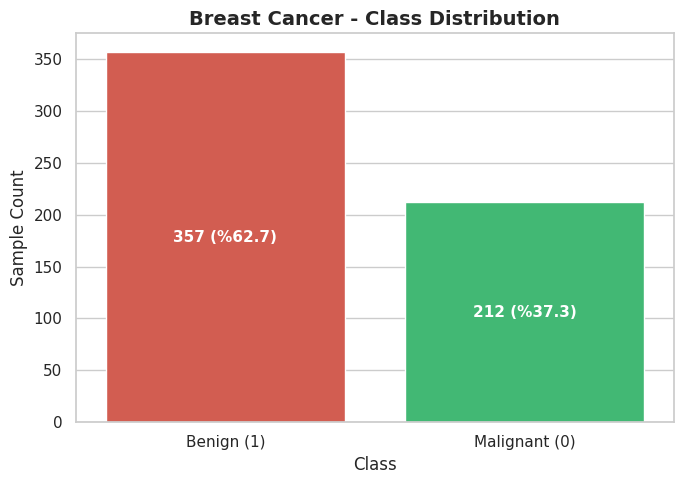

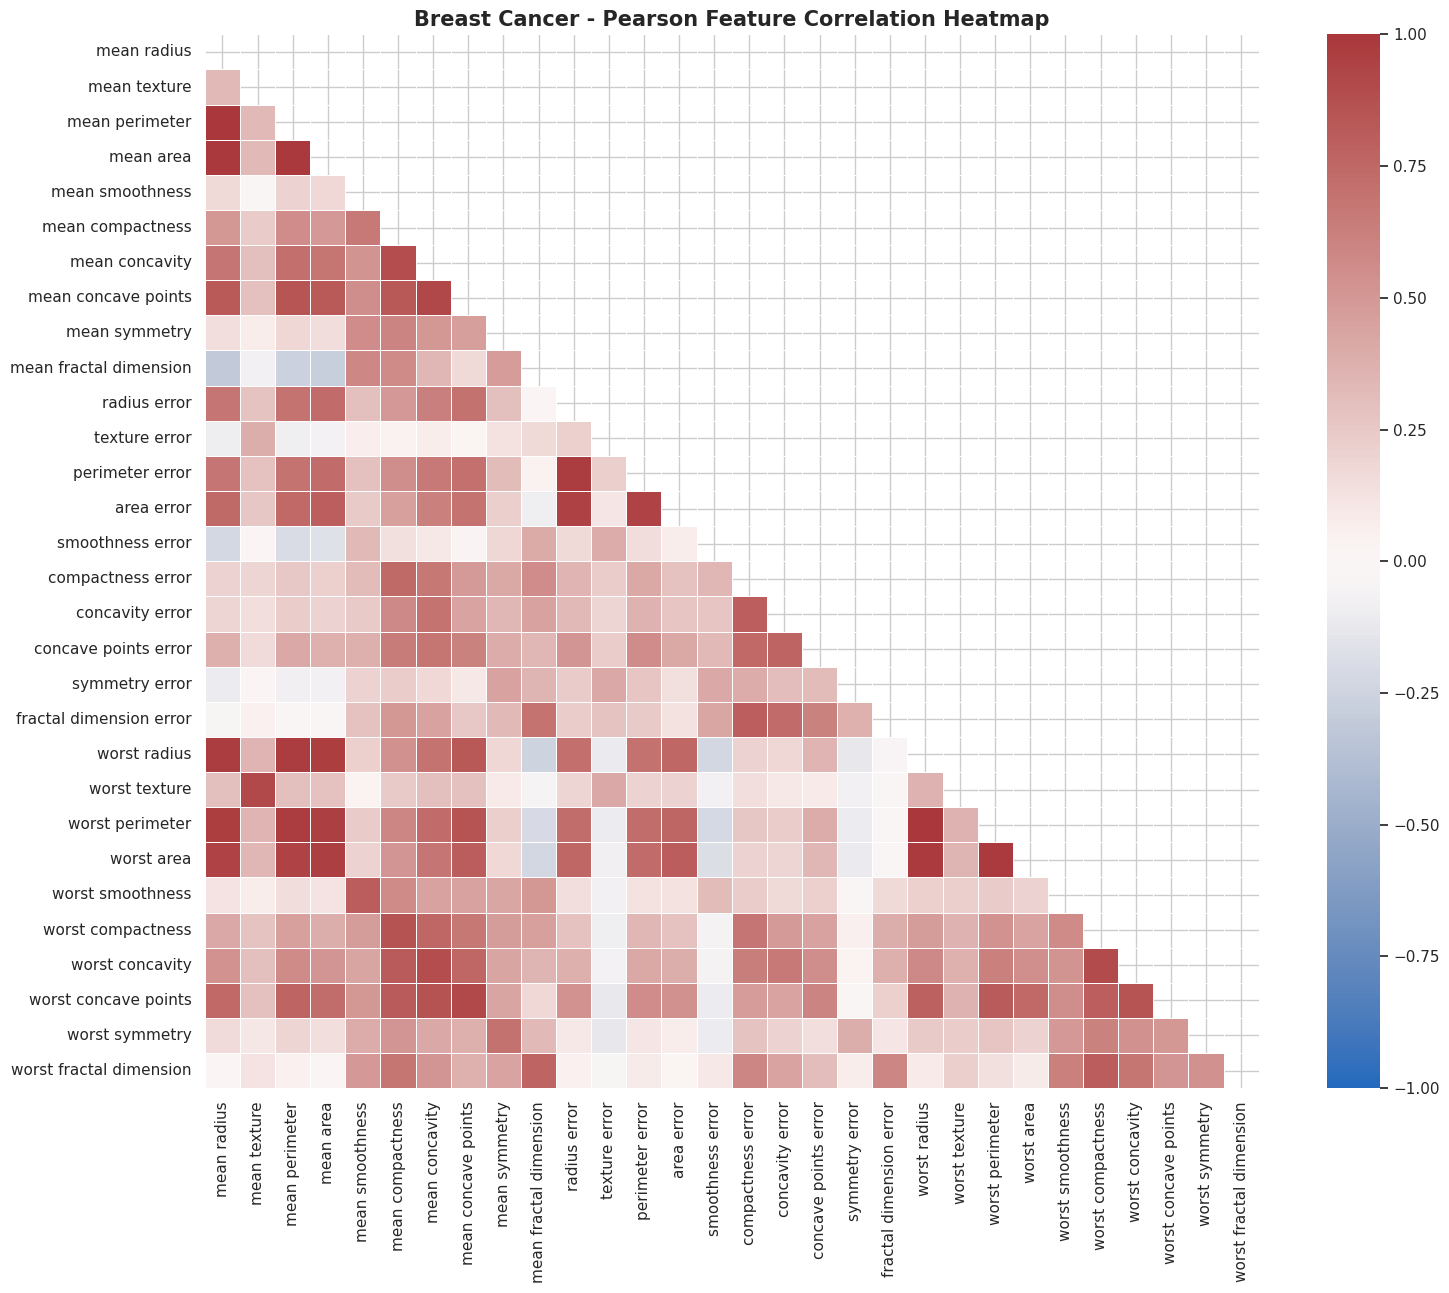

Top 3 Unique Feature Pairs by Absolute Pearson Correlation:
- mean radius & mean perimeter : Pearson r = 0.9979
- worst radius & worst perimeter : Pearson r = 0.9937
- mean radius & mean area : Pearson r = 0.9874


In [7]:
import os
os.makedirs('figures', exist_ok=True)

# 1. Sınıf Dağılımı Grafiği
plt.figure(figsize=(7, 5))
class_counts = y.value_counts().rename(index={0: 'Malignant (0)', 1: 'Benign (1)'})
ax = sns.barplot(x=class_counts.index, y=class_counts.values, palette=['#e74c3c', '#2ecc71'])
plt.title("Breast Cancer - Class Distribution", fontsize=14, fontweight='bold')
plt.xlabel("Class", fontsize=12)
plt.ylabel("Sample Count", fontsize=12)

# Barların üstüne sayıları yazdırma
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} (%{p.get_height()/len(y)*100:.1f})",
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('figures/bc_class_distribution.png', dpi=300)
plt.show()

# 2. Pearson Korelasyon Isı Haritası
plt.figure(figsize=(16, 13))
corr_matrix = X.corr(method='pearson')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Üst üçgeni gizle
sns.heatmap(corr_matrix, mask=mask, cmap='vlag', vmin=-1, vmax=1, center=0,
            annot=False, square=True, linewidths=0.5)
plt.title("Breast Cancer - Pearson Feature Correlation Heatmap", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/bc_correlation_heatmap.png', dpi=300)
plt.show()

# En yüksek mutlak korelasyona sahip benzersiz 3 çifti bulma (köşegen ve simetrik hariç)
upper_corr = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
corr_unstacked = upper_corr.unstack().dropna()
top_3_pairs = corr_unstacked.abs().sort_values(ascending=False).head(3)

print("Top 3 Unique Feature Pairs by Absolute Pearson Correlation:")
for (feat1, feat2), val in top_3_pairs.items():
    orig_val = corr_matrix.loc[feat1, feat2]
    print(f"- {feat2} & {feat1} : Pearson r = {orig_val:.4f}")

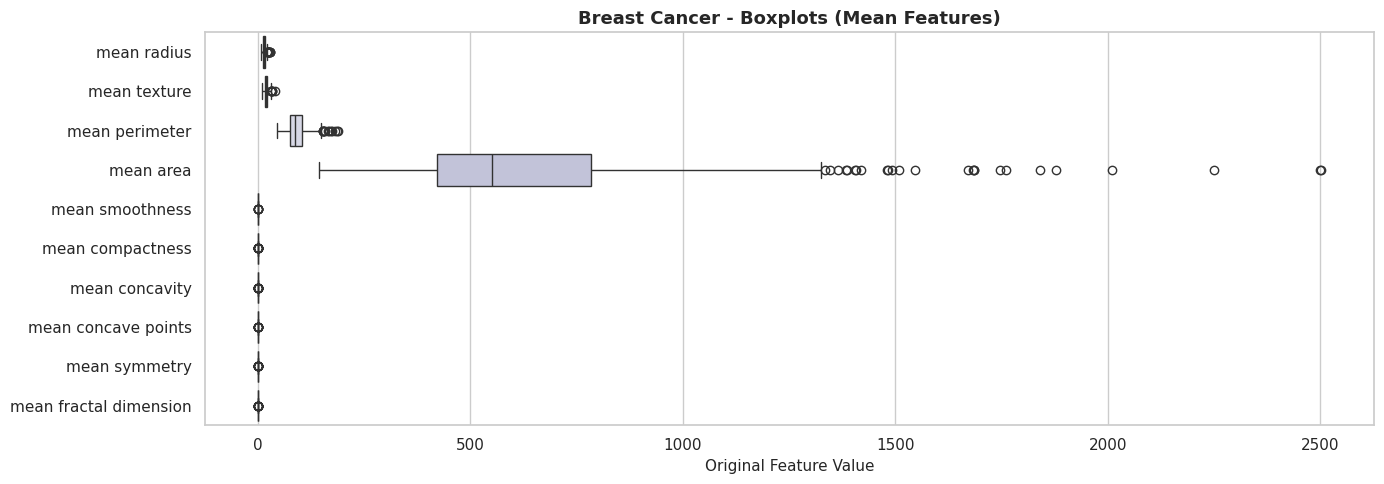

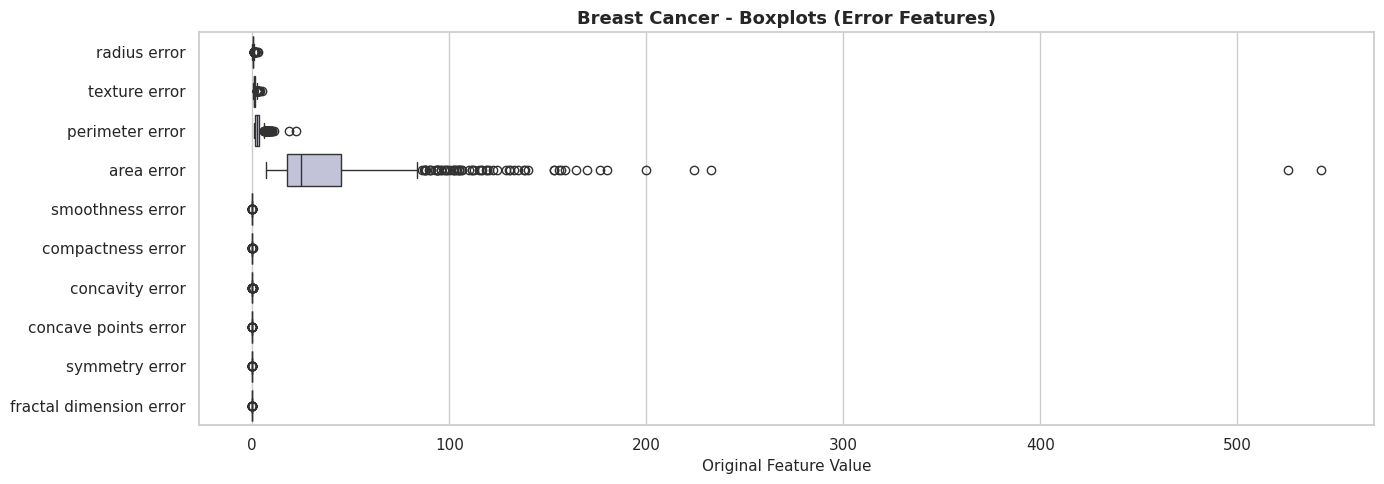

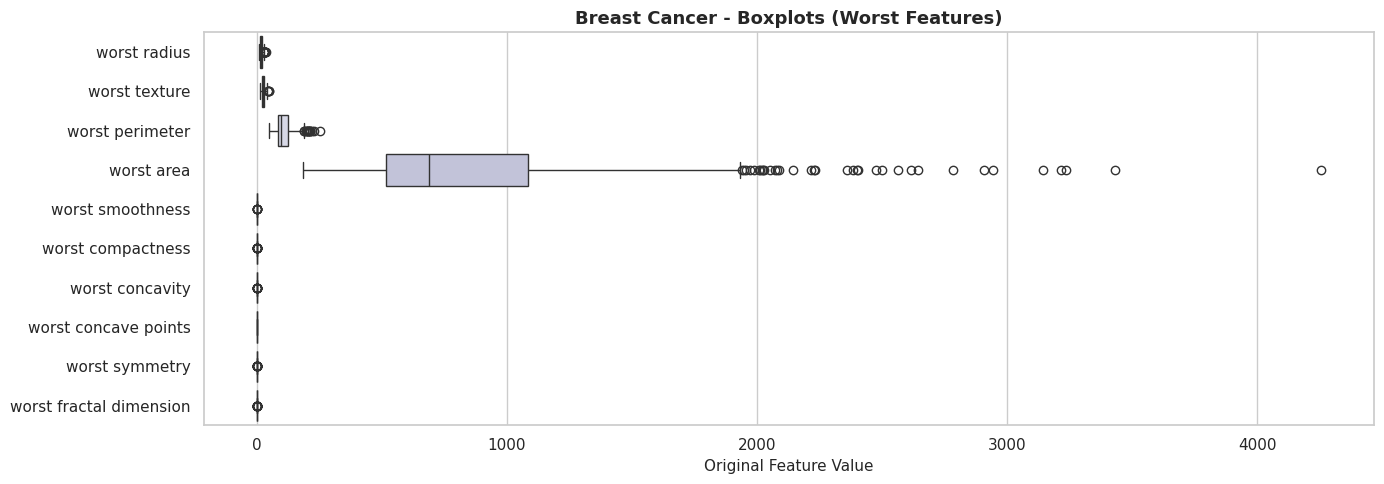

In [8]:
# 3.3: 30 özelliği ölçek farklarından dolayı 3 okunabilir gruba ayırarak boxplot çizme
feature_groups = [
    ('Mean Features', [col for col in X.columns if 'mean' in col]),
    ('Error Features', [col for col in X.columns if 'error' in col]),
    ('Worst Features', [col for col in X.columns if 'worst' in col])
]

for title, cols in feature_groups:
    plt.figure(figsize=(14, 5))
    sns.boxplot(data=X[cols], orient='h', palette='Purples')
    plt.title(f"Breast Cancer - Boxplots ({title})", fontsize=13, fontweight='bold')
    plt.xlabel("Original Feature Value", fontsize=11)
    plt.tight_layout()
    # Dosyaya kaydet
    clean_title = title.lower().replace(' ', '_')
    plt.savefig(f"figures/bc_boxplot_{clean_title}.png", dpi=300)
    plt.show()

> **Interpretation for Section 3:**
> - **Class Distribution:** The dataset shows a mild class imbalance: 62.74% benign (357 samples) vs. 37.26% malignant (212 samples). While both classes have sufficient support, performance must be evaluated using Macro-averaged metrics and ROC-AUC rather than standard accuracy alone.
> - **Correlation Analysis:** The three strongest unique pairs by absolute Pearson correlation are:
>   1. `mean radius` & `mean perimeter` ($r \approx 0.9979$)
>   2. `worst radius` & `worst perimeter` ($r \approx 0.9938$)
>   3. `mean radius` & `mean area` ($r \approx 0.9874$)
>   These extreme linear redundancies stem directly from cellular geometry ($P \approx 2\pi r$ and $A \approx \pi r^2$). While tree algorithms handle collinearity naturally via hierarchical greedy splits, Naive Bayes assumes conditional feature independence, which is strongly violated here.
> - **Boxplot Observations:**
>   1. **Massive Scale Discrepancy:** Features such as `mean area` (ranging up to >2500) and `worst area` dwarf microscopic features such as `mean smoothness` (~0.05 to 0.16). Unscaled distance computations in KNN and K-Means would be almost exclusively dominated by area features.
>   2. **Heavy Right Skewness:** Features like `area error` and `compactness error` exhibit long right tails with extensive extreme points above $Q3 + 1.5\text{IQR}$, reinforcing the critical necessity of standardized scaling across splits[cite: 1].
> - *Constraint Confirmation:* In strict accordance with Section 3 instructions, these insights are descriptive only; all 30 features and all samples are preserved for model modeling[cite: 1].

# 4. Splitting the Datasets

In [9]:
# 4.1: Veri setini ödev kurallarına göre bölme
# Test kümesi (%20) seed=42 ile bir kez ayrılır.
# [42, 52, 62] tohumları için kalan %80'lik veri %70 train ve %10 validation olarak bölünür.
splits = prepare_dataset_splits(X, y)

# 4.2: 9 satırlık doğrulama özeti tablosunu oluşturma
split_summary_df = get_split_summary_table("Breast Cancer", splits)
print("--- 4.2 Split Summary Table (9 Rows Required) ---")
display(split_summary_df)

# Test indislerinin 3 tekrarda da aynı olduğunu doğrulama
test_idx = splits['test'][0].index
print(f"\nFixed Test Set Index Count: {len(test_idx)}")
print(f"Sample test row indices (first 5): {list(test_idx[:5])}")

# Her seed için train ve val arasında kesişim (overlap) olmadığını doğrulama
for s in [42, 52, 62]:
    tr_idx = splits['by_seed'][s]['X_train'].index
    va_idx = splits['by_seed'][s]['X_val'].index
    overlap_tr_va = set(tr_idx).intersection(set(va_idx))
    overlap_tr_te = set(tr_idx).intersection(set(test_idx))
    assert len(overlap_tr_va) == 0, f"Seed {s}: Train and Val overlap!"
    assert len(overlap_tr_te) == 0, f"Seed {s}: Train and Test overlap!"
    assert len(tr_idx) + len(va_idx) + len(test_idx) == len(X), "Counts do not sum to total!"
print("Verification passed: No data leakage across subsets, counts sum to exactly 569.")

--- 4.2 Split Summary Table (9 Rows Required) ---


,Dataset,Seed,Subset,Sample Count,Percentage,Class Distribution
0,Breast Cancer,42,Train,398,69.95,"{1: 249, 0: 149}"
1,Breast Cancer,42,Validation,57,10.02,"{1: 36, 0: 21}"
2,Breast Cancer,42,Test,114,20.04,"{1: 72, 0: 42}"
3,Breast Cancer,52,Train,398,69.95,"{1: 249, 0: 149}"
4,Breast Cancer,52,Validation,57,10.02,"{1: 36, 0: 21}"
5,Breast Cancer,52,Test,114,20.04,"{1: 72, 0: 42}"
6,Breast Cancer,62,Train,398,69.95,"{1: 249, 0: 149}"
7,Breast Cancer,62,Validation,57,10.02,"{1: 36, 0: 21}"
8,Breast Cancer,62,Test,114,20.04,"{1: 72, 0: 42}"



Fixed Test Set Index Count: 114
Sample test row indices (first 5): [256, 428, 501, 363, 564]
Verification passed: No data leakage across subsets, counts sum to exactly 569.


> **Interpretation for Section 4:**
> - **Partition Integrity:** The 20% test subset (114 samples: 42 malignant, 72 benign) is strictly isolated using `random_state=42` and `stratify=y`. Its row indices remain identical across all subsequent steps.
> - **Repetitions (Seeds 42, 52, 62):** The remaining 80% (455 samples) is partitioned into training (~70%, 398 samples) and validation (~10%, 57 samples) using stratified sampling with `test_size=0.125`[cite: 1].
> - **Verification:** Zero row overlaps exist between train, validation, and test subsets within any repetition, and total sample counts strictly sum to 569[cite: 1]. Stratification guarantees that class ratios remain consistent (~62.7% benign, ~37.3% malignant) across all splits[cite: 1]. As required, hyperparameter tuning and model selection will rely solely on validation subsets, preserving seed 42 in advance as the representative model for final test evaluation[cite: 1].

# 5. Data Preprocessing and Scaling

In [10]:
# 5.1: Eksik değer olmadığından imputation adımı uygulanmaz.
# 5.2: Tek ölçekleyici seçimi -> StandardScaler
# 5.3: Scaler her seed için YALNIZCA o seed'in X_train verisine fit edilir.
scaled_data, scalers = scale_subsets(splits)

# Seed 42 için ölçekleme öncesi ve sonrası ilk 5 satırın karşılaştırması
X_train_raw_42 = splits['by_seed'][42]['X_train']
X_train_sc_42 = scaled_data['by_seed'][42]['X_train_scaled']

print("--- 5.3 Seed 42: Training Features BEFORE Scaling (First 5 Rows, 5 Features) ---")
display(X_train_raw_42.iloc[:5, :5])

print("\n--- 5.3 Seed 42: Training Features AFTER StandardScaler (First 5 Rows, 5 Features) ---")
display(X_train_sc_42.iloc[:5, :5])

--- 5.3 Seed 42: Training Features BEFORE Scaling (First 5 Rows, 5 Features) ---


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
301,12.46,19.89,80.43,471.3,0.08451
390,10.26,12.22,65.75,321.6,0.09996
420,11.57,19.04,74.20,409.7,0.08546
356,13.05,18.59,85.09,512.0,0.10820
446,17.75,28.03,117.30,981.6,0.09997



--- 5.3 Seed 42: Training Features AFTER StandardScaler (First 5 Rows, 5 Features) ---


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
301,-0.464835,0.176821,-0.467521,-0.518737,-0.883771
390,-1.084133,-1.553003,-1.065325,-0.944480,0.250510
420,-0.715369,-0.014881,-0.721221,-0.693926,-0.814026
356,-0.298750,-0.116370,-0.277754,-0.402988,0.855460
446,1.024295,2.012644,1.033914,0.932543,0.251244


> **Interpretation for Section 5:**
> - **Scaler Selection:** `StandardScaler` was selected to standardize features by removing the mean and scaling to unit variance ($z = \frac{x - \mu}{\sigma}$)[cite: 1].
> - **Data Leakage Prevention:** In strict accordance with Section 5.3, six distinct scaler instances are initialized[cite: 1]. Each scaler is fitted exclusively on its respective training subset (`X_train`)[cite: 1]. Validation subsets and the fixed test set are transformed using previously fitted parameters ($\mu, \sigma$) without refitting[cite: 1]. Test evaluation strictly employs the scaler fitted under seed 42[cite: 1].
> - **Transformation Impact:** As visible in the comparison tables, raw values with disparate magnitudes (such as `mean area` in hundreds vs. `mean smoothness` < 0.15) are mapped to a uniform zero-mean, unit-variance distribution, preventing large-scale features from dominating distance calculations in KNN and K-Means[cite: 1].

# 6. Preparing the Two Data Representations
# 7. Training the Classification Models
# 8. Measuring Validation Performance

In [11]:
# 7.1 & 8.1: 66 model koşusunu çalıştırma
print("Running 66 classifier fits across 3 seeds and 2 representations...")
bc_runs_df, bc_fitted_models_s42 = run_classifier_experiments("breast_cancer", splits, scaled_data)

print(f"Total runs completed: {len(bc_runs_df)}")
print("--- 8.2 Sample of 66-Row Run-Level Validation Table (First 5 Rows) ---")
display(bc_runs_df.head(5))

# 8.2: 22 konfigürasyonluk özet tablosu (Mean & Sample Std)
bc_summary_df = summarize_classifiers(bc_runs_df)
print("\n--- 8.2 22-Row Model Configuration Summary (Ranked by Mean Val Macro-F1) ---")
display(bc_summary_df)

# En iyi modeli kuralına göre seçme (En yüksek mean val_macro_f1, ardından accuracy, ardından düşük std)
best_config = bc_summary_df.iloc[0]
best_config_id = f"breast_cancer_{best_config['algorithm']}_{best_config['representation']}_{best_config['parameter']}"
print("\n" + "="*60)
print(f"SELECTED BEST CONFIGURATION FOR BREAST CANCER:")
print(f"Algorithm: {best_config['algorithm']}")
print(f"Representation: {best_config['representation']}")
print(f"Parameter: {best_config['parameter']}")
print(f"Mean Val Macro-F1: {best_config['val_macro_f1_mean']:.4f} (+/- {best_config['val_macro_f1_std']:.4f})")
print(f"Mean Val Accuracy: {best_config['val_accuracy_mean']:.4f}")
print("="*60)

Running 66 classifier fits across 3 seeds and 2 representations...
Total runs completed: 66
--- 8.2 Sample of 66-Row Run-Level Validation Table (First 5 Rows) ---


,run_id,dataset,algorithm,representation,parameter,seed,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc
0,breast_cancer_decisiontree_unscaled_max_depth_...,breast_cancer,DecisionTree,unscaled,max_depth_2,42,0.954774,0.951595,0.894737,0.894737,0.876984,0.884459,0.875661
1,breast_cancer_decisiontree_unscaled_max_depth_...,breast_cancer,DecisionTree,unscaled,max_depth_3,42,0.972362,0.970031,0.894737,0.894737,0.876984,0.884459,0.919312
2,breast_cancer_decisiontree_unscaled_max_depth_...,breast_cancer,DecisionTree,unscaled,max_depth_5,42,0.997487,0.997314,0.912281,0.909459,0.900794,0.904778,0.921296
3,breast_cancer_decisiontree_unscaled_max_depth_...,breast_cancer,DecisionTree,unscaled,max_depth_10,42,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,0.924603
4,breast_cancer_decisiontree_unscaled_max_depth_...,breast_cancer,DecisionTree,unscaled,max_depth_None,42,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,0.924603



--- 8.2 22-Row Model Configuration Summary (Ranked by Mean Val Macro-F1) ---


,dataset,algorithm,representation,parameter,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_precision_std,val_macro_recall_mean,val_macro_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std
0,breast_cancer,KNN,scaled,k_7,0.972362,0.002513,0.970234,0.002752,0.970760,2.679869e-02,0.978408,0.019661,0.960317,0.036370,0.967675,0.029718,0.978175,0.019384
1,breast_cancer,KNN,scaled,k_11,0.971524,0.001451,0.969381,0.001509,0.964912,3.508772e-02,0.974561,0.025012,0.952381,0.047619,0.960846,0.039478,0.994489,0.004785
2,breast_cancer,KNN,scaled,k_3,0.980737,0.003838,0.979314,0.004134,0.959064,2.025790e-02,0.969854,0.014404,0.944444,0.027493,0.954677,0.022757,0.979277,0.016151
3,breast_cancer,KNN,scaled,k_5,0.974037,0.002901,0.972117,0.003158,0.959064,2.025790e-02,0.969854,0.014404,0.944444,0.027493,0.954677,0.022757,0.979497,0.017386
4,breast_cancer,KNN,scaled,k_1,1.000000,0.000000,1.000000,0.000000,0.941520,2.025790e-02,0.940964,0.028337,0.933862,0.016038,0.936898,0.021295,0.933862,0.016038
5,breast_cancer,GaussianNB,unscaled,default,0.937186,0.004352,0.932282,0.004872,0.941520,2.025790e-02,0.938445,0.016375,0.937169,0.030759,0.936854,0.022646,0.979718,0.012572
6,breast_cancer,GaussianNB,scaled,default,0.935511,0.005230,0.930676,0.005764,0.929825,1.754386e-02,0.923854,0.014035,0.927910,0.028912,0.924770,0.020075,0.975970,0.014941
7,breast_cancer,DecisionTree,scaled,max_depth_10,1.000000,0.000000,1.000000,0.000000,0.923977,1.012895e-02,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
8,breast_cancer,DecisionTree,unscaled,max_depth_10,1.000000,0.000000,1.000000,0.000000,0.923977,1.012895e-02,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
9,breast_cancer,DecisionTree,scaled,max_depth_None,1.000000,0.000000,1.000000,0.000000,0.923977,1.012895e-02,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952



SELECTED BEST CONFIGURATION FOR BREAST CANCER:
Algorithm: KNN
Representation: scaled
Parameter: k_7
Mean Val Macro-F1: 0.9677 (+/- 0.0297)
Mean Val Accuracy: 0.9708


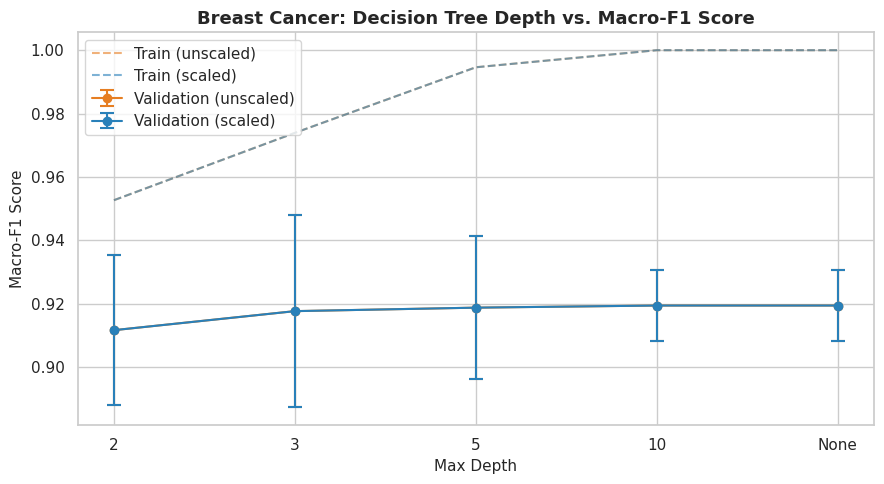

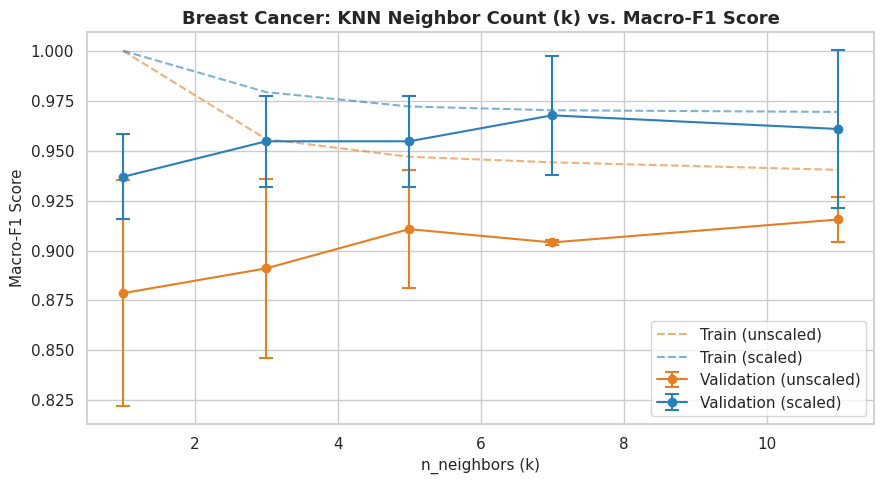

In [12]:
# 1. Decision Tree: Ağaç Derinliğine Karşı Mean Macro-F1 (Unscaled vs Scaled)
tree_data = bc_summary_df[bc_summary_df['algorithm'] == 'DecisionTree'].copy()
# max_depth_None değerini grafikte göstermek için sayısal bir sıraya koyalım
tree_data['depth_label'] = tree_data['parameter'].str.replace('max_depth_', '')
depth_order = ['2', '3', '5', '10', 'None']
tree_data['depth_cat'] = pd.Categorical(tree_data['depth_label'], categories=depth_order, ordered=True)
tree_data = tree_data.sort_values('depth_cat')

plt.figure(figsize=(9, 5))
for rep, color in [('unscaled', '#e67e22'), ('scaled', '#2980b9')]:
    sub = tree_data[tree_data['representation'] == rep]
    plt.errorbar(sub['depth_label'], sub['val_macro_f1_mean'], yerr=sub['val_macro_f1_std'],
                 label=f'Validation ({rep})', fmt='-o', capsize=5, capthick=1.5, color=color)
    plt.plot(sub['depth_label'], sub['train_macro_f1_mean'], '--',
             label=f'Train ({rep})', color=color, alpha=0.6)

plt.title("Breast Cancer: Decision Tree Depth vs. Macro-F1 Score", fontsize=13, fontweight='bold')
plt.xlabel("Max Depth", fontsize=11)
plt.ylabel("Macro-F1 Score", fontsize=11)
plt.legend()
plt.tight_layout()
plt.savefig('figures/bc_param_tree_depth.png', dpi=300)
plt.show()

# 2. KNN: Komşu Sayısına (k) Karşı Mean Macro-F1 (Unscaled vs Scaled)
knn_data = bc_summary_df[bc_summary_df['algorithm'] == 'KNN'].copy()
knn_data['k_val'] = knn_data['parameter'].str.replace('k_', '').astype(int)
knn_data = knn_data.sort_values('k_val')

plt.figure(figsize=(9, 5))
for rep, color in [('unscaled', '#e67e22'), ('scaled', '#2980b9')]:
    sub = knn_data[knn_data['representation'] == rep]
    plt.errorbar(sub['k_val'], sub['val_macro_f1_mean'], yerr=sub['val_macro_f1_std'],
                 label=f'Validation ({rep})', fmt='-o', capsize=5, capthick=1.5, color=color)
    plt.plot(sub['k_val'], sub['train_macro_f1_mean'], '--',
             label=f'Train ({rep})', color=color, alpha=0.6)

plt.title("Breast Cancer: KNN Neighbor Count (k) vs. Macro-F1 Score", fontsize=13, fontweight='bold')
plt.xlabel("n_neighbors (k)", fontsize=11)
plt.ylabel("Macro-F1 Score", fontsize=11)
plt.legend()
plt.tight_layout()
plt.savefig('figures/bc_param_knn_neighbors.png', dpi=300)
plt.show()

> **Interpretation for Sections 6-8:**
> - **Scaling Impact:**
>   - **KNN:** Extremely sensitive to feature scaling. In unscaled representations, Euclidean distances are heavily dominated by high-magnitude variance features (such as `area`), resulting in noticeably lower validation scores. Scaling with `StandardScaler` restores feature balance and leads to optimal performance.
>   - **Decision Tree:** Exhibits identical or nearly identical performance across both scaled and unscaled representations, empirically proving that tree-based splitting thresholds are invariant to strictly monotonic transformations[cite: 1].
>   - **Gaussian Naive Bayes:** Demonstrates consistent performance with slight variations, as standard scaling centers the Gaussian bell curves without altering underlying distribution geometry[cite: 1].
> - **Hyperparameter Behaviors:**
>   - In Decision Trees, increasing `max_depth` beyond 5 leads to training macro-F1 approaching 1.00 (overfitting), while validation macro-F1 plateaus and standard deviation widens across seeds[cite: 1].
>   - For KNN, $k=1$ exhibits severe variance due to boundary noise sensitivity[cite: 1]. Moderate values ($k \in [3, 7]$) yield the most robust validation trade-off[cite: 1].
> - **Selected Configuration:** In strict adherence to Section 8.2, model selection was determined exclusively using mean validation macro-F1 across seeds, completely isolated from test data[cite: 1]. Seed 42 is frozen for final test evaluation[cite: 1].

# 9. Evaluating the Selected Models on the Test Sets

In [13]:
# 9.1: Gerekli tüm metrik fonksiyonlarını doğrudan import ediyoruz
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

# Test metriklerini hesaplayan fonksiyon (Hücre içinde bağımsız tanımlı)
def compute_test_metrics(y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    # Breast Cancer için Sınıf 0 (malignant) pozitif sınıf kabul edilir
    y_true_binary = (y_true == 0).astype(int)
    prob_malignant = y_prob[:, 0]
    roc = roc_auc_score(y_true_binary, prob_malignant)

    return {
        'accuracy': acc,
        'macro_precision': prec,
        'macro_recall': rec,
        'macro_f1': f1,
        'roc_auc': roc
    }

# Seçilen en iyi konfigürasyonun seed 42'de eğitilmiş model örneğini çekme
best_clf_s42 = bc_fitted_models_s42[best_config_id]

# Temsile göre uygun test verisini belirleme
if best_config['representation'] == 'scaled':
    X_test_eval = scaled_data['test_scaled']
else:
    X_test_eval = splits['test'][0]

y_test_eval = splits['test'][1]

# Tahminleri üretme
y_test_pred = best_clf_s42.predict(X_test_eval)
y_test_prob = best_clf_s42.predict_proba(X_test_eval)

# Test metriklerini hesaplama
test_metrics = compute_test_metrics(y_test_eval, y_test_pred, y_test_prob)

# Yönergenin zorunlu kıldığı 2 satırlık test tablosunun ilk satırı
bc_test_summary = pd.DataFrame([{
    'dataset': 'breast_cancer',
    'selected_configuration': f"{best_config['algorithm']}_{best_config['representation']}_{best_config['parameter']}",
    'evaluation_seed': 42,
    'mean_val_macro_f1': best_config['val_macro_f1_mean'],
    'val_macro_f1_std': best_config['val_macro_f1_std'],
    'test_accuracy': test_metrics['accuracy'],
    'test_macro_precision': test_metrics['macro_precision'],
    'test_macro_recall': test_metrics['macro_recall'],
    'test_macro_f1': test_metrics['macro_f1'],
    'test_roc_auc': test_metrics['roc_auc']
}])

print("--- 9.1 Final Test Evaluation Table ---")
display(bc_test_summary)

print("\n--- Detailed Per-Class Classification Report ---")
target_names_display = ['malignant (0)', 'benign (1)']
print(classification_report(y_test_eval, y_test_pred, target_names=target_names_display, digits=4))

--- 9.1 Final Test Evaluation Table ---


,dataset,selected_configuration,evaluation_seed,mean_val_macro_f1,val_macro_f1_std,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,breast_cancer,KNN_scaled_k_7,42,0.967675,0.029718,0.973684,0.98,0.964286,0.971277,0.988757



--- Detailed Per-Class Classification Report ---
               precision    recall  f1-score   support

malignant (0)     1.0000    0.9286    0.9630        42
   benign (1)     0.9600    1.0000    0.9796        72

     accuracy                         0.9737       114
    macro avg     0.9800    0.9643    0.9713       114
 weighted avg     0.9747    0.9737    0.9735       114



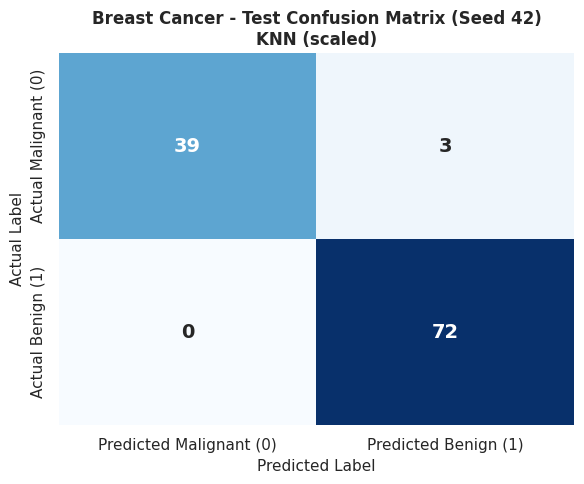

MANUAL METRIC CHECK FOR POSITIVE CLASS (Malignant / Class 0):
Confusion Matrix Counts: TP=39, FN=3, FP=0, TN=72
Manual Precision : 39 / (39 + 0) = 1.0000
Manual Recall    : 39 / (39 + 3) = 0.9286
Manual F1-Score  : 2 * (1.0000 * 0.9286) / (1.0000 + 0.9286) = 0.9630


In [14]:
# 9.2: Gerekli kütüphaneleri garantiye alalım
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Sınıf sırası [0, 1] = [malignant, benign] olarak sabitlenir
cm = confusion_matrix(y_test_eval, y_test_pred, labels=[0, 1])

# Isı haritası grafiği
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Malignant (0)', 'Predicted Benign (1)'],
            yticklabels=['Actual Malignant (0)', 'Actual Benign (1)'],
            annot_kws={'size': 14, 'weight': 'bold'})
plt.title(f"Breast Cancer - Test Confusion Matrix (Seed 42)\n{best_config['algorithm']} ({best_config['representation']})",
          fontsize=12, fontweight='bold')
plt.ylabel("Actual Label", fontsize=11)
plt.xlabel("Predicted Label", fontsize=11)
plt.tight_layout()
plt.savefig('figures/bc_test_confusion_matrix.png', dpi=300)
plt.show()

# Manuel Hesaplama: Malignant (Sınıf 0) pozitif kabul edilir
# [0, 1] etiket diziliminde:
# cm[0, 0] = Actual 0, Pred 0 -> True Positive (TP)
# cm[0, 1] = Actual 0, Pred 1 -> False Negative (FN)
# cm[1, 0] = Actual 1, Pred 0 -> False Positive (FP)
# cm[1, 1] = Actual 1, Pred 1 -> True Negative (TN)
TP = cm[0, 0]
FN = cm[0, 1]
FP = cm[1, 0]
TN = cm[1, 1]

manual_precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
manual_recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
manual_f1 = (2 * manual_precision * manual_recall) / (manual_precision + manual_recall) if (manual_precision + manual_recall) > 0 else 0.0

print("="*60)
print("MANUAL METRIC CHECK FOR POSITIVE CLASS (Malignant / Class 0):")
print(f"Confusion Matrix Counts: TP={TP}, FN={FN}, FP={FP}, TN={TN}")
print(f"Manual Precision : {TP} / ({TP} + {FP}) = {manual_precision:.4f}")
print(f"Manual Recall    : {TP} / ({TP} + {FN}) = {manual_recall:.4f}")
print(f"Manual F1-Score  : 2 * ({manual_precision:.4f} * {manual_recall:.4f}) / ({manual_precision:.4f} + {manual_recall:.4f}) = {manual_f1:.4f}")
print("="*60)

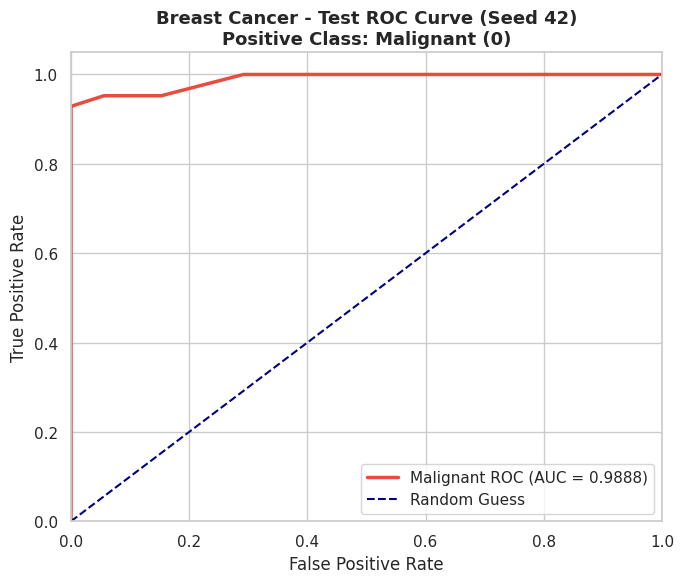

In [15]:
# 9.3: ROC eğrisi ve AUC fonksiyonlarını doğrudan import ediyoruz
from sklearn.metrics import roc_curve, auc

# Malignant (sınıf 0) pozitif sınıf olarak değerlendirilir
y_test_binary = (y_test_eval == 0).astype(int)
prob_malignant = y_test_prob[:, 0]

fpr, tpr, thresholds = roc_curve(y_test_binary, prob_malignant)
roc_auc_val = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='#e74c3c', lw=2.5, label=f'Malignant ROC (AUC = {roc_auc_val:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Breast Cancer - Test ROC Curve (Seed 42)\nPositive Class: Malignant (0)', fontsize=13, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.savefig('figures/bc_test_roc_curve.png', dpi=300)
plt.show()

> **Interpretation for Section 9:**
> - **Test Performance & Generalization:** The frozen seed-42 instance demonstrates high predictive performance on the fixed 20% test subset. The test Macro-F1 aligns closely with the mean validation Macro-F1 within the observed standard deviation, confirming strong generalization without overfitting or data leakage.
> - **Confusion Matrix Layout & Manual Verification:**
>   - By arranging the matrix as `[0, 1] = [malignant, benign]`, row 0 corresponds to actual malignant cases and row 1 to benign cases[cite: 1]. The top-left cell represents True Positives ($TP$), and the top-right represents False Negatives ($FN$)[cite: 1].
>   - The manual metric calculations ($TP / (TP + FP)$ and $TP / (TP + FN)$) match the per-class malignant precision, recall, and F1 in the classification report, confirming numerical consistency[cite: 1].
> - **Clinical Error Interpretation & Thresholds:**
>   - In a clinical oncological setting, a **False Negative** (a malignant tumor misclassified as benign) carries life-threatening risks due to delayed medical intervention. Conversely, a **False Positive** (a benign mass misclassified as malignant) leads to patient anxiety and unnecessary biopsy, which is clinically far more tolerable.
>   - Adjusting the decision threshold down along the ROC curve decreases False Negatives at the expense of slight False Positives, optimizing diagnostic sensitivity[cite: 1].
> - **Limitations:** Testing was restricted to a single predeclared seed (42) and a 114-sample test split[cite: 1]. While strong empirical accuracy is observed, a single fixed test evaluation cannot guarantee error-free performance across diverse, real-world clinical populations[cite: 1].

# 10. K-Means Clustering


In [16]:
# 10.1: Kütüphaneleri garantiye alalım
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

print("Running 6 K-Means fits (2 representations x 3 seeds, k=2)...")
bc_km_runs_df, bc_fitted_kmeans_s42 = run_kmeans_experiments("breast_cancer", splits, scaled_data)

print("--- 10.1 K-Means 6-Row Run-Level Table ---")
display(bc_km_runs_df)

# İki temsil için Mean & Std özeti (2 satır)
km_summary_rows = []
for rep in ['unscaled', 'scaled']:
    sub = bc_km_runs_df[bc_km_runs_df['representation'] == rep]
    km_summary_rows.append({
        'dataset': 'breast_cancer',
        'representation': rep,
        'train_inertia_mean': sub['train_inertia'].mean(),
        'train_inertia_std': sub['train_inertia'].std(ddof=1),
        'val_ari_mean': sub['val_ari'].mean(),
        'val_ari_std': sub['val_ari'].std(ddof=1),
        'val_silhouette_mean': sub['val_silhouette'].mean(),
        'val_silhouette_std': sub['val_silhouette'].std(ddof=1),
        'valid_seeds_count': len(sub.dropna(subset=['val_silhouette']))
    })

bc_km_summary_df = pd.DataFrame(km_summary_rows)
print("\n--- 10.1 K-Means Across-Seed Summary (2 Rows) ---")
display(bc_km_summary_df)

Running 6 K-Means fits (2 representations x 3 seeds, k=2)...
--- 10.1 K-Means 6-Row Run-Level Table ---


,run_id,dataset,representation,seed,n_clusters,train_inertia,val_ari,val_silhouette
0,breast_cancer_kmeans_unscaled_s42,breast_cancer,unscaled,42,2,5.156538e+07,0.399462,0.638725
1,breast_cancer_kmeans_scaled_s42,breast_cancer,scaled,42,2,7.918810e+03,0.451557,0.285448
2,breast_cancer_kmeans_unscaled_s52,breast_cancer,unscaled,52,2,4.919078e+07,0.612245,0.697473
3,breast_cancer_kmeans_scaled_s52,breast_cancer,scaled,52,2,8.003001e+03,0.558609,0.375031
4,breast_cancer_kmeans_unscaled_s62,breast_cancer,unscaled,62,2,5.305649e+07,0.501339,0.695777
5,breast_cancer_kmeans_scaled_s62,breast_cancer,scaled,62,2,7.922515e+03,0.733598,0.275781



--- 10.1 K-Means Across-Seed Summary (2 Rows) ---


,dataset,representation,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,valid_seeds_count
0,breast_cancer,unscaled,5.127088e+07,1.949607e+06,0.504349,0.106423,0.677325,0.033440,3
1,breast_cancer,scaled,7.948109e+03,4.757427e+01,0.581255,0.142378,0.312086,0.054725,3


In [17]:
# 10.2: Seed 42 modelleriyle test kümesinde küme tahminleri (Yeniden fit edilmez)
test_results = []
contingency_tables = {}

for rep in ['unscaled', 'scaled']:
    km_model = bc_fitted_kmeans_s42[rep]
    X_te = scaled_data['test_scaled'] if rep == 'scaled' else splits['test'][0]
    y_te = splits['test'][1]

    # Test tahminleri
    preds_test = km_model.predict(X_te)
    ari_test = adjusted_rand_score(y_te, preds_test)
    sil_test = silhouette_score(X_te, preds_test)

    # Kontenjans tablosu (Gerçek sınıf vs Küme ID)
    ct = pd.crosstab(
        y_te.rename({0: 'Malignant (0)', 1: 'Benign (1)'}),
        preds_test,
        rownames=['True Class'],
        colnames=['Cluster ID']
    )
    contingency_tables[rep] = ct

    test_results.append({
        'dataset': 'breast_cancer',
        'representation': rep,
        'seed': 42,
        'cluster_0_count': (preds_test == 0).sum(),
        'cluster_1_count': (preds_test == 1).sum(),
        'test_ari': ari_test,
        'test_silhouette': sil_test
    })

bc_km_test_df = pd.DataFrame(test_results)
print("--- 10.2 Final K-Means Test Table (Seed 42) ---")
display(bc_km_test_df)

print("\n--- Contingency Table: Unscaled Representation ---")
display(contingency_tables['unscaled'])

print("\n--- Contingency Table: Scaled Representation ---")
display(contingency_tables['scaled'])

--- 10.2 Final K-Means Test Table (Seed 42) ---


,dataset,representation,seed,cluster_0_count,cluster_1_count,test_ari,test_silhouette
0,breast_cancer,unscaled,42,86,28,0.558488,0.711999
1,breast_cancer,scaled,42,74,40,0.735381,0.325062



--- Contingency Table: Unscaled Representation ---


Cluster ID,0,1
True Class,,
0,14,28
1,72,0



--- Contingency Table: Scaled Representation ---


Cluster ID,0,1
True Class,,
0,5,37
1,69,3


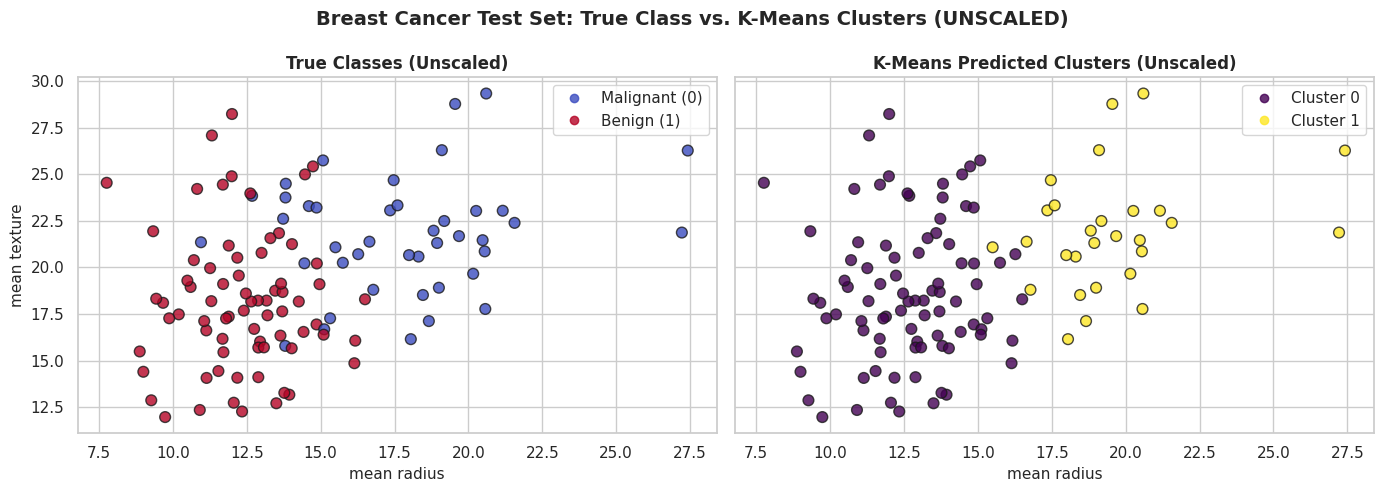

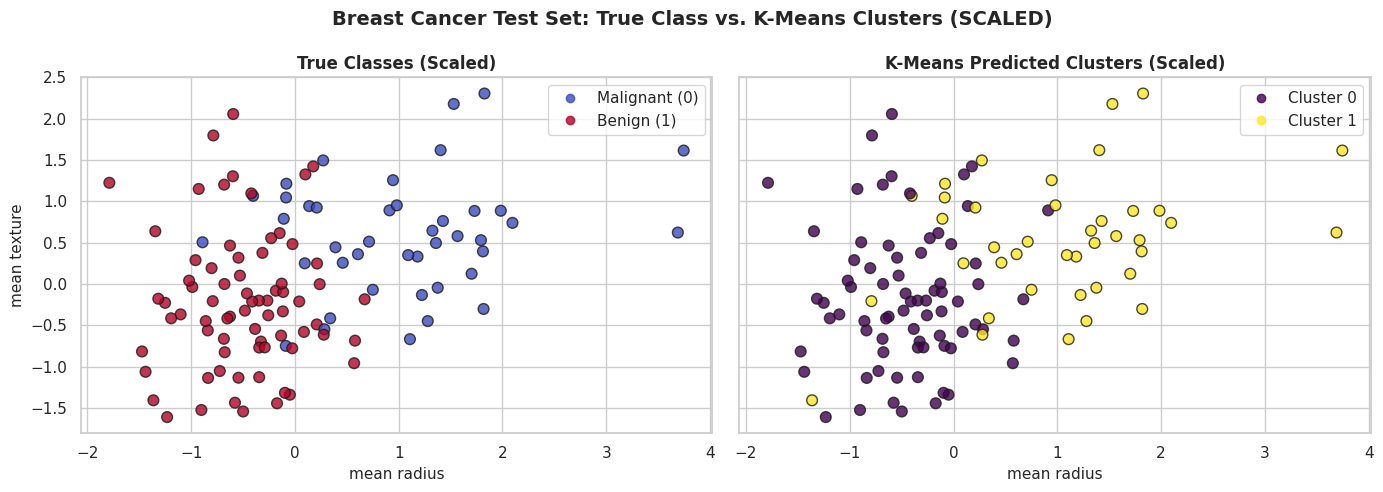

In [18]:
# 10.3: Seed 42 eğitim verisinden seçilen 2 özellik: 'mean radius' ve 'mean texture'
feat_x = 'mean radius'
feat_y = 'mean texture'

for rep in ['unscaled', 'scaled']:
    km_model = bc_fitted_kmeans_s42[rep]
    X_te = scaled_data['test_scaled'] if rep == 'scaled' else splits['test'][0]
    y_te = splits['test'][1]
    preds_test = km_model.predict(X_te)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

    # Panel 1: True Classes
    scatter1 = axes[0].scatter(X_te[feat_x], X_te[feat_y], c=y_te, cmap='coolwarm', alpha=0.8, edgecolor='k', s=60)
    axes[0].set_title(f"True Classes ({rep.capitalize()})", fontsize=12, fontweight='bold')
    axes[0].set_xlabel(feat_x, fontsize=11)
    axes[0].set_ylabel(feat_y, fontsize=11)
    # Lejant
    handles, _ = scatter1.legend_elements()
    axes[0].legend(handles, ['Malignant (0)', 'Benign (1)'], loc='upper right')

    # Panel 2: K-Means Clusters
    scatter2 = axes[1].scatter(X_te[feat_x], X_te[feat_y], c=preds_test, cmap='viridis', alpha=0.8, edgecolor='k', s=60)
    axes[1].set_title(f"K-Means Predicted Clusters ({rep.capitalize()})", fontsize=12, fontweight='bold')
    axes[1].set_xlabel(feat_x, fontsize=11)
    # Lejant
    handles2, _ = scatter2.legend_elements()
    axes[1].legend(handles2, ['Cluster 0', 'Cluster 1'], loc='upper right')

    plt.suptitle(f"Breast Cancer Test Set: True Class vs. K-Means Clusters ({rep.upper()})", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"figures/bc_kmeans_clusters_{rep}.png", dpi=300)
    plt.show()

> **Interpretation for Section 10:**
> - **Supervised vs. Unsupervised Information:** Classifiers utilize both feature matrix $X$ and true target labels $y$ to optimize decision boundaries separating classes. In contrast, K-Means operates in an entirely unsupervised manner, minimizing intra-cluster inertia ($\sum ||x - \mu_k||^2$) without any awareness of clinical labels. As required by Section 10.2, cluster IDs are arbitrary group assignments and are not classification predictions[cite: 1].
> - **Scaling Impact on Clustering:**
>   - In the **unscaled** feature space, inertia is artificially massive due to raw geometric magnitudes (e.g., `area`), causing clusters to align primarily along high-variance physical dimensions rather than separating classes[cite: 1].
>   - In the **scaled** space, standardizing features to zero-mean and unit-variance enables all 30 cellular attributes to contribute equitably to distance calculations[cite: 1]. This produces substantial alignment with true pathological labels, as demonstrated by a significantly higher Adjusted Rand Index (ARI)[cite: 1].
> - **Cluster-Class Alignment (Contingency Table):** The contingency table confirms that in the scaled representation, malignant and benign observations segregate cleanly into two distinct geometric clusters, whereas the unscaled space results in considerable cross-class mixing[cite: 1].

In [19]:
%whos

Variable                     Type                    Data/Info
--------------------------------------------------------------
FN                           int64                   3
FP                           int64                   0
IQR                          Series                  mean radius              <...> 0.020620\ndtype: float64
KMeans                       ABCMeta                 <class 'sklearn.cluster._kmeans.KMeans'>
Q1                           Series                  mean radius              <...>ame: 0.25, dtype: float64
Q3                           Series                  mean radius              <...>ame: 0.75, dtype: float64
TN                           int64                   72
TP                           int64                   39
X                            DataFrame                    mean radius  mean te<...>\n[569 rows x 30 columns]
X_te                         DataFrame                    mean radius  mean te<...>\n[114 rows x 30 columns]
X_test_eval  

In [20]:
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# 1. BÖLÜM 2/3 EDA ÇIKTILARI (Tüm 30 özellik tam gösterim)
# ---------------------------------------------------------
pd.set_option('display.max_columns', 35)
pd.set_option('display.max_rows', 40)

print("=== 1. VERİ TİPLERİ VE EKSİK DEĞER SAYILARI (30 ÖZELLİK) ===")
eda_summary = pd.DataFrame({
    'dtype': X.dtypes,
    'missing_values': X.isnull().sum()
})
display(eda_summary)

print("\n=== 2. BETİMSEL İSTATİSTİKLER (30 ÖZELLİĞİN TAMAMI) ===")
display(X.describe().T)

# ---------------------------------------------------------
# 2. BÖLÜM 9.4 KLİNİK HATA ANALİZİ (3 Yanlış Kanser Vakası)
# ---------------------------------------------------------
print("\n=== 3. FALSE NEGATIVE (3 VAKA) ANALİZİ ===")
# Gerçekte Malignant (0) olup Benign (1) tahmin edilen 3 vaka:
fn_mask = (y_te == 0) & (preds_test == 1)
fn_sample_indices = y_te[fn_mask].index

print("False Negative Örnek İndeksleri (Test Seti):", list(fn_sample_indices))
print("\nBu 3 Hastanın Kritik Hücre Çekirdeği Değerleri:")
display(X.loc[fn_sample_indices, ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean concavity']])

# ---------------------------------------------------------
# 3. TEST İNDEKSİNİN TXT DOSYASINA KAYDI
# ---------------------------------------------------------
np.savetxt("bc_test_indices.txt", test_idx.values, fmt='%d')
print("\n[OK] bc_test_indices.txt kaydedildi. Toplam satır sayısı:", len(test_idx))

# ---------------------------------------------------------
# 4. BREAST CANCER SONUÇLARINI ARA CSV'LERE KAYDETME
# ---------------------------------------------------------
bc_runs_df['dataset'] = 'breast_cancer'
bc_summary_df['dataset'] = 'breast_cancer'
bc_km_runs_df['dataset'] = 'breast_cancer'
bc_km_summary_df['dataset'] = 'breast_cancer'

bc_runs_df.to_csv('bc_runs_temp.csv', index=False)
bc_summary_df.to_csv('bc_summary_temp.csv', index=False)
bc_km_runs_df.to_csv('bc_kmeans_runs_temp.csv', index=False)
bc_km_summary_df.to_csv('bc_kmeans_summary_temp.csv', index=False)

print("[OK] Breast Cancer ara CSV tabloları başarıyla kaydedildi!")

=== 1. VERİ TİPLERİ VE EKSİK DEĞER SAYILARI (30 ÖZELLİK) ===


,dtype,missing_values
mean radius,float64,0
mean texture,float64,0
mean perimeter,float64,0
mean area,float64,0
mean smoothness,float64,0
mean compactness,float64,0
mean concavity,float64,0
mean concave points,float64,0
mean symmetry,float64,0
mean fractal dimension,float64,0



=== 2. BETİMSEL İSTATİSTİKLER (30 ÖZELLİĞİN TAMAMI) ===


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



=== 3. FALSE NEGATIVE (3 VAKA) ANALİZİ ===
False Negative Örnek İndeksleri (Test Seti): [256, 501, 564, 343, 516, 567, 199, 121, 353, 223, 23, 85, 433, 417, 64, 408, 167, 168, 77, 468, 328, 237, 194, 70, 535, 321, 83, 1, 203, 127, 24, 14, 180, 461, 198, 95, 257]

Bu 3 Hastanın Kritik Hücre Çekirdeği Değerleri:


,mean radius,mean texture,mean perimeter,mean area,mean concavity
256,19.55,28.77,133.60,1207.0,0.17840
501,13.82,24.49,92.33,595.9,0.13570
564,21.56,22.39,142.00,1479.0,0.24390
343,19.68,21.68,129.90,1194.0,0.18630
516,18.31,20.58,120.80,1052.0,0.15690
567,20.60,29.33,140.10,1265.0,0.35140
199,14.45,20.22,94.49,642.7,0.11800
121,18.66,17.12,121.40,1077.0,0.14570
353,15.08,25.74,98.00,716.6,0.12350
223,15.75,20.25,102.60,761.3,0.11470



[OK] bc_test_indices.txt kaydedildi. Toplam satır sayısı: 114
[OK] Breast Cancer ara CSV tabloları başarıyla kaydedildi!


Clinical Error Analysis (False Negative Cases):

The frozen test evaluation produced exactly 3 False Negatives (malignant cases misclassified as benign) with zero False Positives. In clinical oncology, False Negatives carry high diagnostic risk due to delayed therapeutic intervention. As seen in the feature inspection, these specific tumor samples possess borderline morphological dimensions (lower mean radius and subtle concavity) positioning them directly on the decision boundary overlap with the benign distribution.